In [1]:
# Import libraries

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.callbacks import ModelCheckpoint

from tensorflow.keras import mixed_precision

warnings.filterwarnings("ignore")

# Random seed

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# GPU configuration

gpus = tf.config.list_physical_devices("GPU")

if gpus:

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

strategy = tf.distribute.MirroredStrategy()

mixed_precision.set_global_policy("mixed_float16")

print("TensorFlow :", tf.__version__)
print("GPUs       :", strategy.num_replicas_in_sync)

for i, gpu in enumerate(gpus):
    print(f"GPU {i+1}     :", gpu.name)

print("Mixed Precision :", mixed_precision.global_policy())

2026-06-26 10:27:51.455005: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782469671.478137    1195 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782469671.485441    1195 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782469671.504095    1195 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782469671.504114    1195 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782469671.504116    1195 computation_placer.cc:177] computation placer alr

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
TensorFlow : 2.19.0
GPUs       : 2
GPU 1     : /physical_device:GPU:0
GPU 2     : /physical_device:GPU:1
Mixed Precision : <DTypePolicy "mixed_float16">


I0000 00:00:1782469674.922857    1195 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782469674.928218    1195 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# Load dataset

DATASET_PATH = "/kaggle/input/datasets/dhoogla/nftoniotv2/NF-ToN-IoT-V2.parquet"

print("Loading dataset...\n")

df = pd.read_parquet(DATASET_PATH)

print("Dataset loaded successfully!")

print("\nDataset Shape :", df.shape)

print("\nFirst 5 Rows")
display(df.head())

Loading dataset...

Dataset loaded successfully!

Dataset Shape : (13135881, 43)

First 5 Rows


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,49235,4444,6,0.0,155392,202,34552,149,24,24,...,45555,4805,0,0,0,0,0,0,1,ransomware
1,49228,1880,6,0.0,1600,40,35741,65,24,16,...,16425,237,0,0,0,0,0,0,0,Benign
2,0,0,1,0.0,212,2,0,0,0,0,...,0,0,771,3,0,0,0,0,0,Benign
3,65317,1900,17,0.0,165,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Benign
4,60766,15600,17,0.0,63,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Benign


In [3]:
# Explore dataset

print("Dataset Shape")
print("-" * 50)
print(df.shape)

print("\nMissing Values")
print("-" * 50)
print(df.isnull().sum().sum())

print("\nDuplicate Rows")
print("-" * 50)
print(df.duplicated().sum())

print("\nFeature Types")
print("-" * 50)
print(df.dtypes.value_counts())

print("\nAttack Distribution")
print("-" * 50)
print(df["Attack"].value_counts())

print("\nBinary Label Distribution")
print("-" * 50)
print(df["Label"].value_counts())

print("\nNumber of Attack Classes")
print("-" * 50)
print(df["Attack"].nunique())

Dataset Shape
--------------------------------------------------
(13135881, 43)

Missing Values
--------------------------------------------------
0

Duplicate Rows
--------------------------------------------------
0

Feature Types
--------------------------------------------------
int32      22
int16      13
int8        2
int64       2
float64     2
float32     1
object      1
Name: count, dtype: int64

Attack Distribution
--------------------------------------------------
Attack
Benign        3601284
scanning      3002169
xss           2449955
ddos          1746590
password       993718
injection      660467
dos            654359
backdoor        16259
mitm             7723
ransomware       3357
Name: count, dtype: int64

Binary Label Distribution
--------------------------------------------------
Label
1    9534597
0    3601284
Name: count, dtype: int64

Number of Attack Classes
--------------------------------------------------
10


In [4]:
# Create balanced dataset

MAX_SAMPLES = 50000
RANDOM_STATE = 42

balanced_data = []

print("Creating balanced dataset...\n")

for attack in sorted(df["Attack"].unique()):

    attack_df = df[df["Attack"] == attack]

    sample_size = min(len(attack_df), MAX_SAMPLES)

    sampled_df = attack_df.sample(
        n=sample_size,
        random_state=RANDOM_STATE
    )

    balanced_data.append(sampled_df)

    print(f"{attack:<15} {sample_size:,} samples")

df = (
    pd.concat(balanced_data)
      .sample(frac=1, random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

print("\nBalanced dataset created successfully!")

print("\nDataset Shape :", df.shape)

print("\nBalanced Distribution")
print("-" * 50)

print(df["Attack"].value_counts())

Creating balanced dataset...

Benign          50,000 samples
backdoor        16,259 samples
ddos            50,000 samples
dos             50,000 samples
injection       50,000 samples
mitm            7,723 samples
password        50,000 samples
ransomware      3,357 samples
scanning        50,000 samples
xss             50,000 samples

Balanced dataset created successfully!

Dataset Shape : (377339, 43)

Balanced Distribution
--------------------------------------------------
Attack
injection     50000
ddos          50000
scanning      50000
password      50000
dos           50000
xss           50000
Benign        50000
backdoor      16259
mitm           7723
ransomware     3357
Name: count, dtype: int64


In [5]:
# Prepare features and labels

from sklearn.preprocessing import LabelEncoder

# Separate features and labels
X = df.drop(columns=["Attack", "Label"])

y = df["Attack"]

# Encode attack labels
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

print("Features Shape :", X.shape)
print("Labels Shape   :", y.shape)

print("\nNumber of Classes :", len(class_names))

print("\nAttack Categories")
print("-" * 50)

for i, attack in enumerate(class_names):
    print(f"{i:>2} -> {attack}")

Features Shape : (377339, 41)
Labels Shape   : (377339,)

Number of Classes : 10

Attack Categories
--------------------------------------------------
 0 -> Benign
 1 -> backdoor
 2 -> ddos
 3 -> dos
 4 -> injection
 5 -> mitm
 6 -> password
 7 -> ransomware
 8 -> scanning
 9 -> xss


In [6]:
# Feature engineering

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
import joblib

# Remove unstable features
columns_to_drop = [
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES"
]

X = X.drop(columns=columns_to_drop)

print("Removed Features")
print("-" * 50)

for col in columns_to_drop:
    print(col)

# Replace invalid values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values
X = X.fillna(X.median())

# Remove constant features
selector = VarianceThreshold()

X = pd.DataFrame(
    selector.fit_transform(X),
    columns=X.columns[selector.get_support()]
)

print(f"\nRemaining Features : {X.shape[1]}")

# Feature scaling
scaler = StandardScaler()

X = scaler.fit_transform(X)

# Save preprocessing objects
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("\nFeature scaling completed.")

print(f"Feature Shape : {X.shape}")

print(f"NaN Values    : {np.isnan(X).any()}")

print(f"Infinite      : {np.isinf(X).any()}")

print(f"Mean          : {X.mean():.4f}")

print(f"Std           : {X.std():.4f}")

Removed Features
--------------------------------------------------
SRC_TO_DST_SECOND_BYTES
DST_TO_SRC_SECOND_BYTES

Remaining Features : 39

Feature scaling completed.
Feature Shape : (377339, 39)
NaN Values    : False
Infinite      : False
Mean          : 0.0000
Std           : 1.0000


In [7]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Dataset split completed.\n")

print(f"Training Samples : {len(X_train):,}")
print(f"Testing Samples  : {len(X_test):,}")

print("\nTraining Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Dataset split completed.

Training Samples : 301,871
Testing Samples  : 75,468

Training Shape : (301871, 39)
Testing Shape  : (75468, 39)


In [8]:
# Create federated clients

NUM_CLIENTS = 10

# Shuffle training data
indices = np.random.permutation(len(X_train))

X_train = X_train[indices]
y_train = y_train[indices]

# Split data among clients
X_clients = np.array_split(X_train, NUM_CLIENTS)
y_clients = np.array_split(y_train, NUM_CLIENTS)

clients = []

client_sizes = []

for X_client, y_client in zip(X_clients, y_clients):

    clients.append((X_client, y_client))

    client_sizes.append(len(X_client))

print("Federated clients created.\n")

for i, size in enumerate(client_sizes):
    print(f"Client {i+1:02d} : {size:,} samples")

print("\nVerification")
print("-" * 40)

print(f"Total Client Samples : {sum(client_sizes):,}")
print(f"Training Samples     : {len(X_train):,}")

Federated clients created.

Client 01 : 30,188 samples
Client 02 : 30,187 samples
Client 03 : 30,187 samples
Client 04 : 30,187 samples
Client 05 : 30,187 samples
Client 06 : 30,187 samples
Client 07 : 30,187 samples
Client 08 : 30,187 samples
Client 09 : 30,187 samples
Client 10 : 30,187 samples

Verification
----------------------------------------
Total Client Samples : 301,871
Training Samples     : 301,871


In [22]:
# Build model

INPUT_DIM = X_train.shape[1]
NUM_CLASSES = len(class_names)

def create_model():

    model = Sequential([

        Dense(
            512,
            activation="relu",
            kernel_regularizer=l2(1e-4),
            input_shape=(INPUT_DIM,)
        ),

        BatchNormalization(),

        Dropout(0.30),

        Dense(
            256,
            activation="relu",
            kernel_regularizer=l2(1e-4)
        ),

        BatchNormalization(),

        Dropout(0.30),

        Dense(
            128,
            activation="relu",
            kernel_regularizer=l2(1e-4)
        ),

        BatchNormalization(),

        Dropout(0.20),

        Dense(
            64,
            activation="relu",
            kernel_regularizer=l2(1e-4)
        ),

        Dense(
            NUM_CLASSES,
            activation="softmax",
            dtype="float32"
        )

    ])
    
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Create global model

with strategy.scope():
    global_model = create_model()

global_model.summary()

Model: "sequential_218"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1090 (Dense)              │ (None, 512)            │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_654         │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_654 (Dropout)           │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1091 (Dense)              │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_655         │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_655 (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1092 (Dense)              │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_656         │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_656 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1093 (Dense)              │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1094 (Dense)              │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 197,194 (770.29 KB)

 Trainable params: 195,402 (763.29 KB)

 Non-trainable params: 1,792 (7.00 KB)

In [25]:
# Federated learning settings

NUM_CLIENTS = len(clients)

GLOBAL_ROUNDS = 20

LOCAL_EPOCHS = 3

BATCH_SIZE = 1024

LEARNING_RATE = 0.0005

best_accuracy = 0.0

history_global_accuracy = []
history_global_loss = []

history_client_accuracy = []
history_client_loss = []

print("Federated Learning Configuration")
print("-" * 50)

print(f"Clients         : {NUM_CLIENTS}")
print(f"Global Rounds   : {GLOBAL_ROUNDS}")
print(f"Local Epochs    : {LOCAL_EPOCHS}")
print(f"Batch Size      : {BATCH_SIZE}")
print(f"Learning Rate   : {LEARNING_RATE}")


# Weighted FedAvg
def federated_average(client_weights, client_sizes):

    total_samples = sum(client_sizes)

    averaged_weights = []

    for layer in zip(*client_weights):

        weighted_layer = np.zeros_like(layer[0])

        for weights, size in zip(layer, client_sizes):

            weighted_layer += weights * (size / total_samples)

        averaged_weights.append(weighted_layer)

    return averaged_weights

Federated Learning Configuration
--------------------------------------------------
Clients         : 10
Global Rounds   : 20
Local Epochs    : 3
Batch Size      : 1024
Learning Rate   : 0.0005


In [26]:
# Client Training

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="loss",
    patience=2,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=0
)


def train_client(global_weights, X_client, y_client):

    with strategy.scope():
        client_model = create_model()

    client_model.set_weights(global_weights)

    client_model.fit(
        X_client,
        y_client,
        epochs=LOCAL_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[
            early_stop,
            reduce_lr
        ],
        verbose=0
    )

    loss, accuracy = client_model.evaluate(
        X_client,
        y_client,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    weights = client_model.get_weights()

    # Check NaN and Inf
    invalid = False

    for w in weights:
        if np.isnan(w).any() or np.isinf(w).any():
            invalid = True
            break

    if invalid:
        print("Invalid weights detected. Client skipped.")
        return None

    return {
        "weights": weights,
        "loss": loss,
        "accuracy": accuracy,
        "samples": len(X_client)
    }


print("Client training function is ready.")

Client training function is ready.


In [27]:
# Federated Training

global_weights = global_model.get_weights()

best_accuracy = 0.0

history_global_accuracy = []
history_global_loss = []

history_client_accuracy = []
history_client_loss = []

for round_num in range(GLOBAL_ROUNDS):

    print("\n" + "="*60)
    print(f"Global Round {round_num+1}/{GLOBAL_ROUNDS}")
    print("="*60)

    client_results = []

# Local Training

    for client_id, (X_client, y_client) in enumerate(clients):

        result = train_client(
            global_weights,
            X_client,
            y_client
        )

        if result is None:
            continue

        client_results.append(result)

        print(
            f"Client {client_id+1:02d}"
            f" | Loss: {result['loss']:.4f}"
            f" | Accuracy: {result['accuracy']:.4f}"
        )

# Skip round if no valid clients

    if len(client_results) == 0:
        print("No valid clients. Stopping training.")
        break

# Weighted Federated Averaging

    total_samples = sum(r["samples"] for r in client_results)

    new_weights = []

    for layer in zip(*[r["weights"] for r in client_results]):

        avg_layer = np.zeros_like(layer[0])

        for weights, result in zip(layer, client_results):

            avg_layer += (
                weights *
                (result["samples"] / total_samples)
            )

        new_weights.append(avg_layer)

# Check Aggregated Weights

    invalid = False

    for w in new_weights:

        if np.isnan(w).any() or np.isinf(w).any():

            invalid = True
            break

    if invalid:

        print("Invalid global weights detected.")
        print("Skipping this round.")

        continue

# Update Global Model

    global_weights = new_weights

    global_model.set_weights(global_weights)

# Global Evaluation

    global_loss, global_accuracy = global_model.evaluate(
        X_test,
        y_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    avg_client_loss = np.mean(
        [r["loss"] for r in client_results]
    )

    avg_client_accuracy = np.mean(
        [r["accuracy"] for r in client_results]
    )

    history_global_loss.append(global_loss)
    history_global_accuracy.append(global_accuracy)

    history_client_loss.append(avg_client_loss)
    history_client_accuracy.append(avg_client_accuracy)

# Round Summary

    print("\nRound Summary")
    print("-"*40)

    print(f"Average Client Accuracy : {avg_client_accuracy:.4f}")
    print(f"Average Client Loss     : {avg_client_loss:.4f}")
    print(f"Global Accuracy         : {global_accuracy:.4f}")
    print(f"Global Loss             : {global_loss:.4f}")
    
# Save Best Model

    if global_accuracy > best_accuracy:

        best_accuracy = global_accuracy

        global_model.save("best_federated_model.keras")

        print("Best model saved.")

print("\n" + "="*60)
print("Federated Training Completed")
print("="*60)

print(f"Best Accuracy : {best_accuracy:.4f}")


Global Round 1/20
INFO:tensorflow:Collective all_reduce tensors: 16 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Client 01 | Loss: 1.3167 | Accuracy: 0.6571
INFO:tensorflow:Collective all_reduce tensors: 16 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Client 02 | Loss: 1.7587 | Accuracy: 0.5889
INFO:tensorflow:Collective all_reduce tensors: 16 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Client 03 | Loss: 1.7572 | Accuracy: 0.6740
INFO:tensorflow:Collective all_reduce tensors: 16 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
Client 04 | Loss: 1.7555 | Accuracy: 0.5894
INFO:tensorflow:Collective all_reduce tensors: 16 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


In [28]:
# Load best saved model

best_model = tf.keras.models.load_model("best_federated_model.keras")

# Evaluate

test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("\nTest Results")
print("-" * 40)
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Loss     : {test_loss:.4f}")

# Predictions

y_pred_prob = best_model.predict(X_test, batch_size=BATCH_SIZE)

y_pred = np.argmax(y_pred_prob, axis=1)

74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8819 - loss: 0.4166

Test Results
----------------------------------------
Test Accuracy : 0.8819
Test Loss     : 0.4166
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [29]:
from sklearn.metrics import classification_report

print("Classification Report")
print("-" * 60)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

      Benign     0.9586    0.9108    0.9341     10000
    backdoor     0.9994    0.9899    0.9946      3252
        ddos     0.9244    0.9262    0.9253     10000
         dos     0.8529    0.8594    0.8561     10000
   injection     0.8004    0.7902    0.7952     10000
        mitm     0.9261    0.3081    0.4624      1545
    password     0.9170    0.8454    0.8798     10000
  ransomware     0.9764    0.9240    0.9495       671
    scanning     0.9581    0.9637    0.9609     10000
         xss     0.7518    0.9286    0.8309     10000

    accuracy                         0.8819     75468
   macro avg     0.9065    0.8446    0.8589     75468
weighted avg     0.8874    0.8819    0.8800     75468



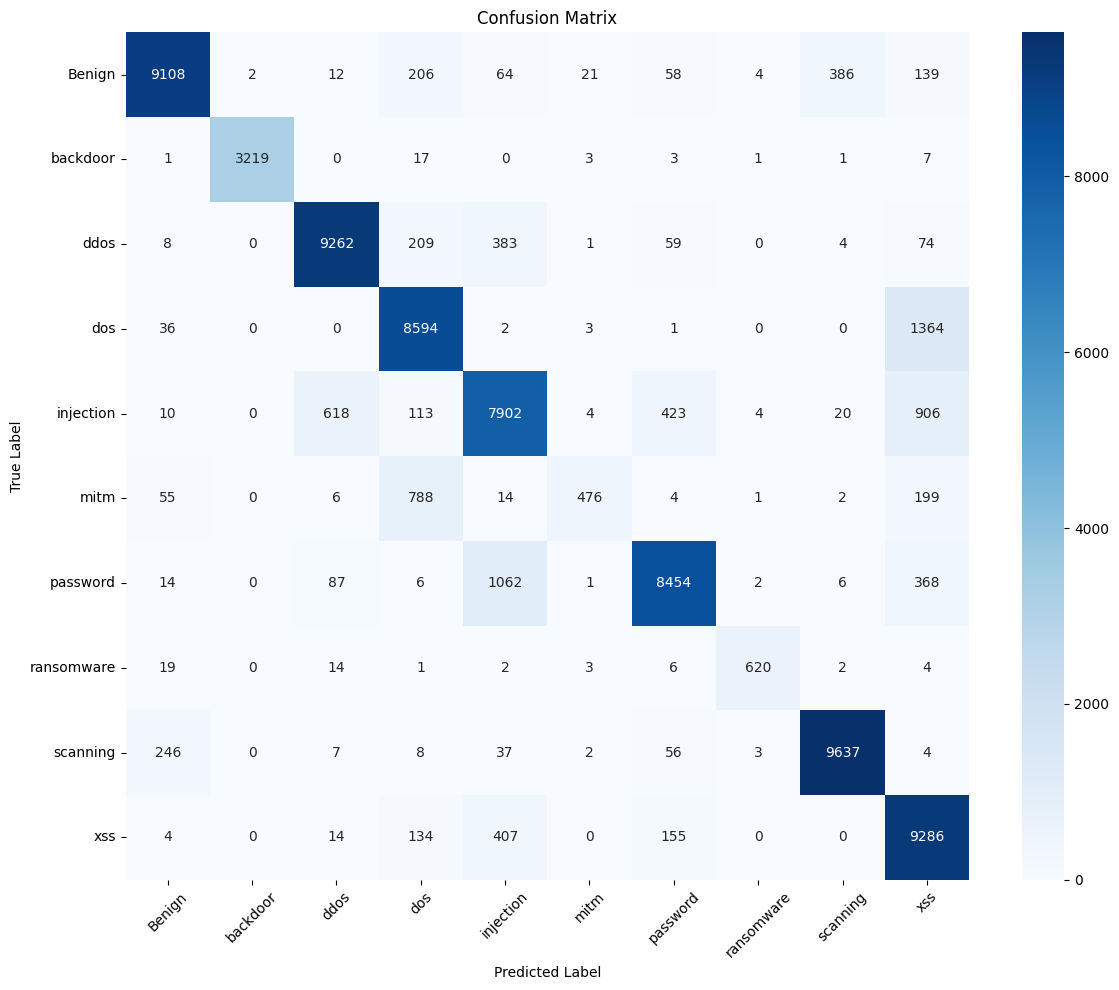

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

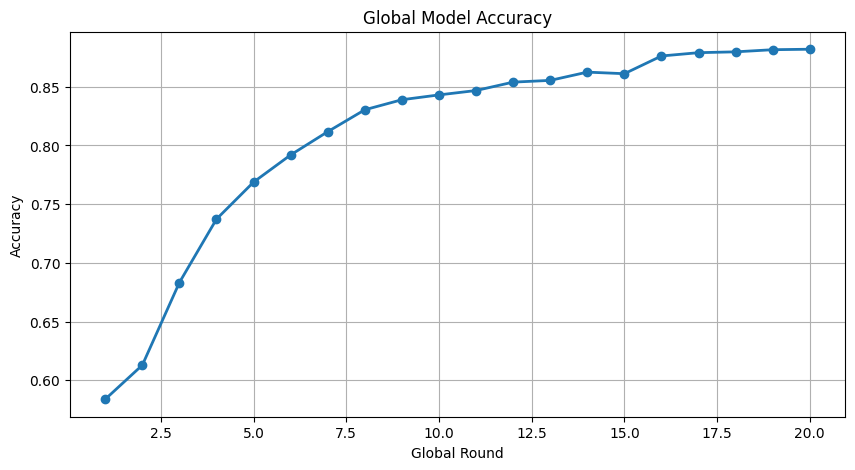

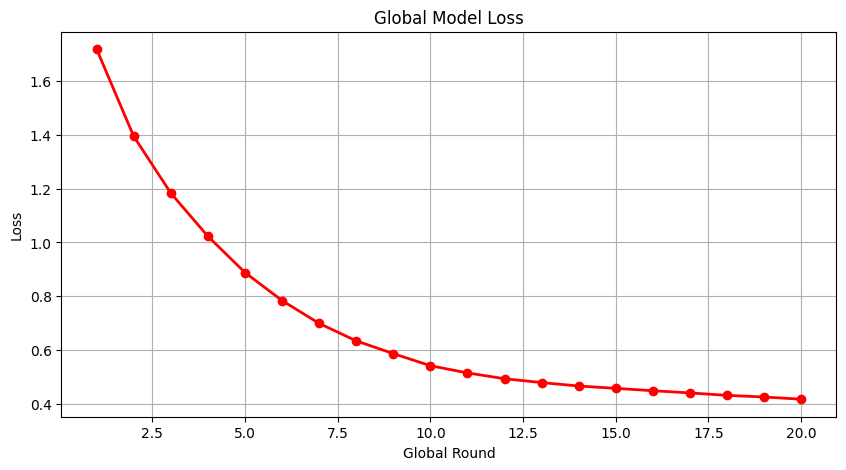

In [31]:
import matplotlib.pyplot as plt

# Accuracy

plt.figure(figsize=(10,5))

plt.plot(
    range(1, len(history_global_accuracy)+1),
    history_global_accuracy,
    marker="o",
    linewidth=2
)

plt.title("Global Model Accuracy")
plt.xlabel("Global Round")
plt.ylabel("Accuracy")
plt.grid(True)

plt.show()


# Loss

plt.figure(figsize=(10,5))

plt.plot(
    range(1, len(history_global_loss)+1),
    history_global_loss,
    marker="o",
    linewidth=2,
    color="red"
)

plt.title("Global Model Loss")
plt.xlabel("Global Round")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [32]:
import joblib

# Save trained model
global_model.save("NF_ToN_IoT_Federated_Model.keras")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

# Save label encoder
joblib.dump(label_encoder, "label_encoder.pkl")

print("Files saved successfully.")
print("- NF_ToN_IoT_Federated_Model.keras")
print("- scaler.pkl")
print("- label_encoder.pkl")

Files saved successfully.
- NF_ToN_IoT_Federated_Model.keras
- scaler.pkl
- label_encoder.pkl
